In [4]:
# AML Data Validation System
# Module 1: Data Profiling

print("================================")
print("AML DATA VALIDATION SYSTEM")
print("Module 1: Data Profiling")
print("================================")

AML DATA VALIDATION SYSTEM
Module 1: Data Profiling


In [5]:
transactions = [
    {
        "transaction_id": "T001",
        "customer_id": "C101",
        "amount": 2500,
        "country": "UK"
    },
    {
        "transaction_id": "T002",
        "customer_id": "C102",
        "amount": 7500,
        "country": "UK"
    },
    {
        "transaction_id": "T003",
        "customer_id": "C103",
        "amount": None,
        "country": "USA"
    },
    {
        "transaction_id": "T004",
        "customer_id": "C104",
        "amount": -500,
        "country": "UK"
    },
    {
        "transaction_id": "T005",
        "customer_id": "C105",
        "amount": 12000,
        "country": "UK"
    }
]

print(transactions)

[{'transaction_id': 'T001', 'customer_id': 'C101', 'amount': 2500, 'country': 'UK'}, {'transaction_id': 'T002', 'customer_id': 'C102', 'amount': 7500, 'country': 'UK'}, {'transaction_id': 'T003', 'customer_id': 'C103', 'amount': None, 'country': 'USA'}, {'transaction_id': 'T004', 'customer_id': 'C104', 'amount': -500, 'country': 'UK'}, {'transaction_id': 'T005', 'customer_id': 'C105', 'amount': 12000, 'country': 'UK'}]


In [6]:
total_transactions = len(transactions)

print("Total Transactions:", total_transactions)

Total Transactions: 5


In [7]:
for transaction in transactions:

    if transaction["amount"] is None:

        print(
            transaction["transaction_id"],
            "- Missing Transaction Amount"
        )

T003 - Missing Transaction Amount


In [8]:
# Create a separate test dataset
test_transactions = transactions.copy()

# Add a duplicate transaction
test_transactions.append(transactions[1].copy())

print("Total test transactions:", len(test_transactions))

Total test transactions: 6


In [9]:
seen_transaction_ids = []

for transaction in test_transactions:

    transaction_id = transaction["transaction_id"]

    if transaction_id in seen_transaction_ids:
        print(transaction_id, "- Duplicate Transaction Found")

    else:
        seen_transaction_ids.append(transaction_id)

T002 - Duplicate Transaction Found


In [10]:
for transaction in transactions:

    amount = transaction["amount"]

    if amount is None:
        print(transaction["transaction_id"], "- Missing Amount")

    elif amount <= 0:
        print(transaction["transaction_id"], "- Invalid Amount")

    else:
        print(transaction["transaction_id"], "- Amount Valid")

T001 - Amount Valid
T002 - Amount Valid
T003 - Missing Amount
T004 - Invalid Amount
T005 - Amount Valid


In [11]:
import json

print("JSON library loaded successfully")

JSON library loaded successfully


In [12]:
# Data Profiling Summary

missing_amounts = []
invalid_amounts = []
duplicate_ids = []

seen_ids = []

for transaction in test_transactions:

    transaction_id = transaction["transaction_id"]
    amount = transaction["amount"]

    # Check duplicate IDs
    if transaction_id in seen_ids:
        duplicate_ids.append(transaction_id)
    else:
        seen_ids.append(transaction_id)

    # Check missing amounts
    if amount is None:
        missing_amounts.append(transaction_id)

    # Check invalid amounts
    elif amount <= 0:
        invalid_amounts.append(transaction_id)


print("Missing Amounts:", missing_amounts)
print("Invalid Amounts:", invalid_amounts)
print("Duplicate Transactions:", duplicate_ids)

Missing Amounts: ['T003']
Invalid Amounts: ['T004']
Duplicate Transactions: ['T002']


In [13]:
profiling_report = {
    "project_name": "AML Data Validation System",
    "module": "Data Profiling",
    "total_transactions": len(test_transactions),
    "unique_transaction_ids": len(set(
        t["transaction_id"] for t in test_transactions
    )),
    "missing_amount_transactions": missing_amounts,
    "invalid_amount_transactions": invalid_amounts,
    "duplicate_transaction_ids": duplicate_ids
}

print(profiling_report)

{'project_name': 'AML Data Validation System', 'module': 'Data Profiling', 'total_transactions': 6, 'unique_transaction_ids': 5, 'missing_amount_transactions': ['T003'], 'invalid_amount_transactions': ['T004'], 'duplicate_transaction_ids': ['T002']}


In [14]:
with open("profiling_report.json", "w") as file:

    json.dump(
        profiling_report,
        file,
        indent=4
    )

print("Profiling report created successfully!")

Profiling report created successfully!


In [15]:
with open("profiling_report.json", "r") as file:

    report = json.load(file)

print(json.dumps(report, indent=4))

{
    "project_name": "AML Data Validation System",
    "module": "Data Profiling",
    "total_transactions": 6,
    "unique_transaction_ids": 5,
    "missing_amount_transactions": [
        "T003"
    ],
    "invalid_amount_transactions": [
        "T004"
    ],
    "duplicate_transaction_ids": [
        "T002"
    ]
}


In [16]:
# Identify dataset columns

columns = list(transactions[0].keys())

print("Dataset Columns:")

for column in columns:
    print(column)

Dataset Columns:
transaction_id
customer_id
amount
country


In [17]:
# Count missing values in each column

for column in columns:

    missing_count = 0

    for transaction in transactions:

        if transaction[column] is None:
            missing_count += 1

    print(column, ":", missing_count, "missing values")

transaction_id : 0 missing values
customer_id : 0 missing values
amount : 1 missing values
country : 0 missing values


In [18]:
# Detect data types

for column in columns:

    for transaction in transactions:

        value = transaction[column]

        if value is not None:

            print(column, ":", type(value).__name__)
            break

transaction_id : str
customer_id : str
amount : int
country : str


In [19]:
# Column-level profiling

column_profile = {}

for column in columns:

    values = [
        transaction[column]
        for transaction in transactions
    ]

    missing_count = sum(
        value is None for value in values
    )

    valid_values = [
        value for value in values
        if value is not None
    ]

    detected_type = (
        type(valid_values[0]).__name__
        if valid_values else "Unknown"
    )

    column_profile[column] = {
        "detected_type": detected_type,
        "total_values": len(values),
        "missing_values": missing_count,
        "valid_values": len(valid_values)
    }

print(json.dumps(column_profile, indent=4))

{
    "transaction_id": {
        "detected_type": "str",
        "total_values": 5,
        "missing_values": 0,
        "valid_values": 5
    },
    "customer_id": {
        "detected_type": "str",
        "total_values": 5,
        "missing_values": 0,
        "valid_values": 5
    },
    "amount": {
        "detected_type": "int",
        "total_values": 5,
        "missing_values": 1,
        "valid_values": 4
    },
    "country": {
        "detected_type": "str",
        "total_values": 5,
        "missing_values": 0,
        "valid_values": 5
    }
}


In [20]:
profiling_report["column_profiles"] = column_profile

with open("profiling_report.json", "w") as file:

    json.dump(
        profiling_report,
        file,
        indent=4
    )

print("Updated profiling_report.json successfully!")

Updated profiling_report.json successfully!


In [21]:
# Calculate Data Quality Score

total_records = len(transactions)

valid_records = 0

for transaction in transactions:

    amount = transaction["amount"]

    if amount is not None and amount > 0:
        valid_records += 1

quality_score = (
    valid_records / total_records
) * 100

print("Total Records:", total_records)
print("Valid Records:", valid_records)
print("Data Quality Score:", quality_score, "%")

Total Records: 5
Valid Records: 3
Data Quality Score: 60.0 %


In [22]:
profiling_report["data_quality"] = {
    "total_records": total_records,
    "valid_records": valid_records,
    "quality_score": round(quality_score, 2),
    "scoring_rule": "Positive, non-missing transaction amounts"
}

with open("profiling_report.json", "w") as file:

    json.dump(
        profiling_report,
        file,
        indent=4
    )

print("Data Quality Score added to report!")

Data Quality Score added to report!


In [23]:
with open("profiling_report.json", "r") as file:

    final_report = json.load(file)

print(json.dumps(final_report, indent=4))

{
    "project_name": "AML Data Validation System",
    "module": "Data Profiling",
    "total_transactions": 6,
    "unique_transaction_ids": 5,
    "missing_amount_transactions": [
        "T003"
    ],
    "invalid_amount_transactions": [
        "T004"
    ],
    "duplicate_transaction_ids": [
        "T002"
    ],
    "column_profiles": {
        "transaction_id": {
            "detected_type": "str",
            "total_values": 5,
            "missing_values": 0,
            "valid_values": 5
        },
        "customer_id": {
            "detected_type": "str",
            "total_values": 5,
            "missing_values": 0,
            "valid_values": 5
        },
        "amount": {
            "detected_type": "int",
            "total_values": 5,
            "missing_values": 1,
            "valid_values": 4
        },
        "country": {
            "detected_type": "str",
            "total_values": 5,
            "missing_values": 0,
            "valid_values": 5
       

In [24]:
# Count unique countries

countries = []

for transaction in transactions:

    country = transaction["country"]

    if country not in countries:
        countries.append(country)

print("Unique Countries:", countries)
print("Number of Unique Countries:", len(countries))

Unique Countries: ['UK', 'USA']
Number of Unique Countries: 2


In [25]:
# FINAL DATA PROFILING REPORT

import json

# Use the same dataset for all calculations
data = test_transactions

# 1. Basic information
total_records = len(data)

# 2. Check transaction IDs
seen_ids = []
duplicate_ids = []

for transaction in data:
    tid = transaction["transaction_id"]

    if tid in seen_ids:
        duplicate_ids.append(tid)
    else:
        seen_ids.append(tid)

# 3. Check amounts
missing_amounts = []
invalid_amounts = []
valid_records = 0

for transaction in data:
    amount = transaction["amount"]
    tid = transaction["transaction_id"]

    if amount is None:
        missing_amounts.append(tid)

    elif amount <= 0:
        invalid_amounts.append(tid)

    else:
        valid_records += 1

# 4. Calculate quality score
quality_score = (valid_records / total_records) * 100

# 5. Column profiling
columns = list(data[0].keys())
column_profile = {}

for column in columns:

    values = [t[column] for t in data]

    valid_values = [
        value for value in values
        if value is not None
    ]

    column_profile[column] = {
        "detected_type": (
            type(valid_values[0]).__name__
            if valid_values else "Unknown"
        ),
        "total_values": len(values),
        "missing_values": len(values) - len(valid_values),
        "valid_values": len(valid_values)
    }

# 6. Country analysis
unique_countries = list(set(
    t["country"] for t in data
))

# 7. Build final report
profiling_report = {
    "project_name": "AML Data Validation System",
    "module": "Data Profiling",
    "total_transactions": total_records,
    "unique_transaction_ids": len(seen_ids),
    "duplicate_transaction_ids": duplicate_ids,
    "missing_amount_transactions": missing_amounts,
    "invalid_amount_transactions": invalid_amounts,
    "column_profiles": column_profile,
    "unique_countries": unique_countries,
    "data_quality": {
        "valid_records": valid_records,
        "total_records": total_records,
        "quality_score": round(quality_score, 2),
        "scoring_rule": "Positive, non-missing transaction amounts"
    }
}

# 8. Save report
with open("profiling_report.json", "w") as file:
    json.dump(profiling_report, file, indent=4)

print("Final Profiling Report Created!")
print("Total Records:", total_records)
print("Valid Records:", valid_records)
print("Data Quality Score:", round(quality_score, 2), "%")
print("Duplicate IDs:", duplicate_ids)
print("Missing Amounts:", missing_amounts)
print("Invalid Amounts:", invalid_amounts)

Final Profiling Report Created!
Total Records: 6
Valid Records: 4
Data Quality Score: 66.67 %
Duplicate IDs: ['T002']
Missing Amounts: ['T003']
Invalid Amounts: ['T004']


In [26]:
from google.colab import files

files.download("profiling_report.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
cardinality_profile = {}

for column in columns:

    values = [
        transaction[column]
        for transaction in test_transactions
        if transaction[column] is not None
    ]

    unique_values = set(values)

    cardinality_profile[column] = {
        "unique_values": len(unique_values),
        "total_non_missing_values": len(values)
    }

print(json.dumps(cardinality_profile, indent=4))

{
    "transaction_id": {
        "unique_values": 5,
        "total_non_missing_values": 6
    },
    "customer_id": {
        "unique_values": 5,
        "total_non_missing_values": 6
    },
    "amount": {
        "unique_values": 4,
        "total_non_missing_values": 5
    },
    "country": {
        "unique_values": 2,
        "total_non_missing_values": 6
    }
}


In [28]:
columns = list(test_transactions[0].keys())

print(columns)

['transaction_id', 'customer_id', 'amount', 'country']


In [29]:
cardinality_profile = {}

for column in columns:

    values = [
        transaction[column]
        for transaction in test_transactions
        if transaction[column] is not None
    ]

    unique_values = set(values)

    cardinality_profile[column] = {
        "unique_values": len(unique_values),
        "total_non_missing_values": len(values)
    }

print(json.dumps(cardinality_profile, indent=4))

{
    "transaction_id": {
        "unique_values": 5,
        "total_non_missing_values": 6
    },
    "customer_id": {
        "unique_values": 5,
        "total_non_missing_values": 6
    },
    "amount": {
        "unique_values": 4,
        "total_non_missing_values": 5
    },
    "country": {
        "unique_values": 2,
        "total_non_missing_values": 6
    }
}


In [30]:
profiling_report["cardinality_analysis"] = cardinality_profile

with open("profiling_report.json", "w") as file:
    json.dump(profiling_report, file, indent=4)

print("Cardinality Analysis added successfully!")

Cardinality Analysis added successfully!


In [31]:
mixed_data = {
    "transaction_id": "T006",
    "customer_id": "C106",
    "amount": "5000",
    "country": "UK"
}

test_transactions.append(mixed_data)

print(test_transactions[-1])

{'transaction_id': 'T006', 'customer_id': 'C106', 'amount': '5000', 'country': 'UK'}


In [33]:
type_profile = {}

for column in columns:

    detected_types = set()

    for transaction in test_transactions:
        value = transaction[column]

        if value is not None:
            detected_types.add(type(value).__name__)

    type_profile[column] = {
        "detected_types": list(detected_types),
        "is_mixed_type": len(detected_types) > 1
    }

print(json.dumps(type_profile, indent=4))

{
    "transaction_id": {
        "detected_types": [
            "str"
        ],
        "is_mixed_type": false
    },
    "customer_id": {
        "detected_types": [
            "str"
        ],
        "is_mixed_type": false
    },
    "amount": {
        "detected_types": [
            "str",
            "int"
        ],
        "is_mixed_type": true
    },
    "country": {
        "detected_types": [
            "str"
        ],
        "is_mixed_type": false
    }
}


In [35]:
profiling_report["mixed_data_type_analysis"] = type_profile

with open("profiling_report.json", "w") as file:
    json.dump(profiling_report, file, indent=4)

print("Mixed Data Type Analysis added successfully!")

Mixed Data Type Analysis added successfully!


In [36]:
transaction_counts = [3, 5, 2, 4, 8, 6, 7]

for i, transaction in enumerate(test_transactions):
    transaction["transaction_count"] = transaction_counts[i]

print(json.dumps(test_transactions, indent=4))

[
    {
        "transaction_id": "T001",
        "customer_id": "C101",
        "amount": 2500,
        "country": "UK",
        "transaction_count": 3
    },
    {
        "transaction_id": "T002",
        "customer_id": "C102",
        "amount": 7500,
        "country": "UK",
        "transaction_count": 5
    },
    {
        "transaction_id": "T003",
        "customer_id": "C103",
        "amount": null,
        "country": "USA",
        "transaction_count": 2
    },
    {
        "transaction_id": "T004",
        "customer_id": "C104",
        "amount": -500,
        "country": "UK",
        "transaction_count": 4
    },
    {
        "transaction_id": "T005",
        "customer_id": "C105",
        "amount": 12000,
        "country": "UK",
        "transaction_count": 8
    },
    {
        "transaction_id": "T002",
        "customer_id": "C102",
        "amount": 7500,
        "country": "UK",
        "transaction_count": 6
    },
    {
        "transaction_id": "T006",
        

In [37]:
amounts = []

for transaction in test_transactions:
    try:
        amount = float(transaction["amount"])

        if transaction["amount"] is not None:
            amounts.append(amount)

    except (ValueError, TypeError):
        continue

amounts.sort()

print("Minimum:", min(amounts))
print("Maximum:", max(amounts))
print("Average:", round(sum(amounts) / len(amounts), 2))

middle = len(amounts) // 2

if len(amounts) % 2 == 0:
    median = (amounts[middle - 1] + amounts[middle]) / 2
else:
    median = amounts[middle]

print("Median:", median)

Minimum: -500.0
Maximum: 12000.0
Average: 5666.67
Median: 6250.0


In [38]:
import pandas as pd

numeric_data = []

for transaction in test_transactions:
    try:
        amount = float(transaction["amount"])
        count = transaction["transaction_count"]

        if amount > 0:
            numeric_data.append({
                "amount": amount,
                "transaction_count": count
            })

    except (ValueError, TypeError):
        continue

df = pd.DataFrame(numeric_data)

correlation = df.corr()

print(correlation)

                     amount  transaction_count
amount             1.000000           0.770615
transaction_count  0.770615           1.000000


In [39]:
profiling_report["distribution_analysis"] = {
    "minimum": min(amounts),
    "maximum": max(amounts),
    "average": round(sum(amounts) / len(amounts), 2),
    "median": median
}

profiling_report["correlation_analysis"] = {
    "amount_transaction_count": round(
        correlation.loc["amount", "transaction_count"], 4
    )
}

with open("profiling_report.json", "w") as file:
    json.dump(profiling_report, file, indent=4)

print("Distribution and Correlation Analysis saved successfully!")

Distribution and Correlation Analysis saved successfully!


In [40]:
pii_keywords = [
    "name",
    "email",
    "phone",
    "address",
    "national_id",
    "passport",
    "date_of_birth"
]

pii_columns = []

for column in columns:
    if any(keyword in column.lower() for keyword in pii_keywords):
        pii_columns.append(column)

print("Potential PII Columns:", pii_columns)

Potential PII Columns: []


In [41]:
profiling_report["pii_detection"] = {
    "potential_pii_columns": pii_columns,
    "pii_columns_found": len(pii_columns)
}

with open("profiling_report.json", "w") as file:
    json.dump(profiling_report, file, indent=4)

print("PII Detection added successfully!")

PII Detection added successfully!


In [42]:
suspicious_keywords = [
    "risk",
    "flag",
    "sanction",
    "suspicious",
    "unusual",
    "alert",
    "watchlist"
]

suspicious_columns = []

for column in columns:
    if any(keyword in column.lower()
           for keyword in suspicious_keywords):
        suspicious_columns.append(column)

print("Potential Suspicious Columns:", suspicious_columns)

Potential Suspicious Columns: []


In [43]:
profiling_report["suspicious_column_detection"] = {
    "potential_suspicious_columns": suspicious_columns,
    "columns_found": len(suspicious_columns)
}

with open("profiling_report.json", "w") as file:
    json.dump(profiling_report, file, indent=4)

print("Suspicious Column Detection added successfully!")

Suspicious Column Detection added successfully!


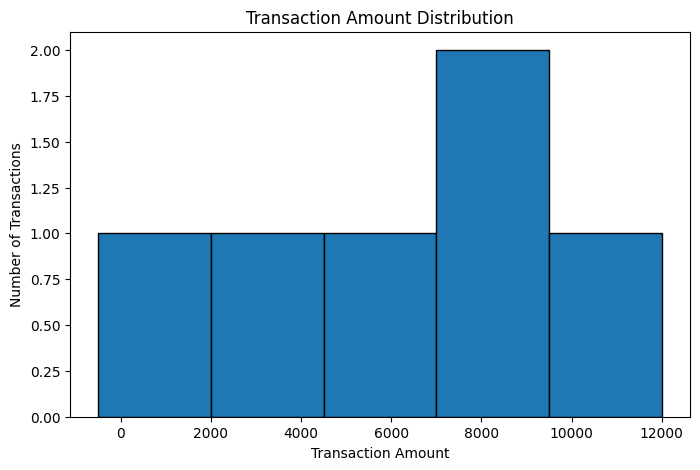

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(amounts, bins=5, edgecolor="black")

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.show()

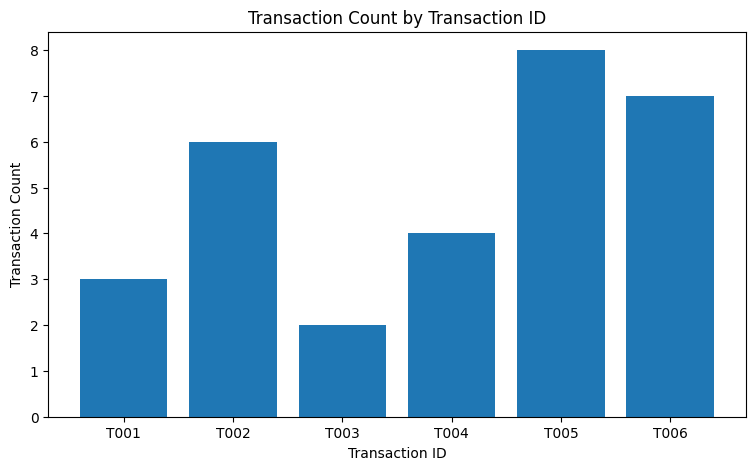

In [45]:
transaction_ids = [
    transaction["transaction_id"]
    for transaction in test_transactions
]

transaction_counts = [
    transaction["transaction_count"]
    for transaction in test_transactions
]

plt.figure(figsize=(9, 5))

plt.bar(transaction_ids, transaction_counts)

plt.title("Transaction Count by Transaction ID")
plt.xlabel("Transaction ID")
plt.ylabel("Transaction Count")

plt.show()

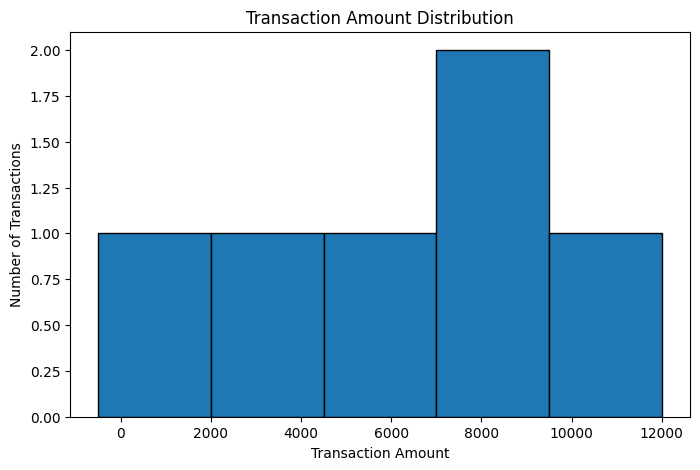

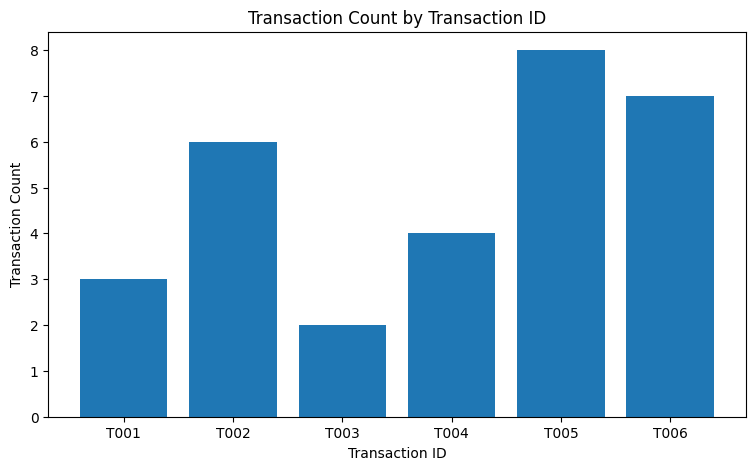

Both charts saved successfully!


In [46]:
# Save Transaction Amount Histogram
plt.figure(figsize=(8, 5))
plt.hist(amounts, bins=5, edgecolor="black")
plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.savefig("transaction_amount_distribution.png")
plt.show()

# Save Transaction Count Bar Chart
plt.figure(figsize=(9, 5))
plt.bar(transaction_ids, transaction_counts)
plt.title("Transaction Count by Transaction ID")
plt.xlabel("Transaction ID")
plt.ylabel("Transaction Count")
plt.savefig("transaction_count_chart.png")
plt.show()

print("Both charts saved successfully!")

In [47]:
!pip install fastapi uvicorn

In [50]:
from fastapi import FastAPI

app = FastAPI(
    title="AML Data Profiling API",
    description="API for AML transaction data profiling",
    version="1.0.0"
)

@app.get("/")
def home():
    return {
        "message": "Welcome to AML Data Profiling API",
        "status": "Running"
    }

@app.get("/profile")
def get_profile():
    return profiling_report

In [51]:
print(type(profiling_report))
print(profiling_report.keys())

<class 'dict'>
dict_keys(['project_name', 'module', 'total_transactions', 'unique_transaction_ids', 'duplicate_transaction_ids', 'missing_amount_transactions', 'invalid_amount_transactions', 'column_profiles', 'unique_countries', 'data_quality', 'cardinality_analysis', 'mixed_data_type_analysis', 'distribution_analysis', 'correlation_analysis', 'pii_detection', 'suspicious_column_detection'])


In [ ]:
import nest_asyncio
import uvicorn

nest_asyncio.apply()

uvicorn.run(app, host="0.0.0.0", port=8000)

In [53]:
import nest_asyncio
import uvicorn

nest_asyncio.apply()

config = uvicorn.Config(
    app,
    host="0.0.0.0",
    port=8000
)

server = uvicorn.Server(config)

await server.serve()

INFO:     Started server process [714]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     Shutting down
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.
INFO:     Finished server process [714]


In [54]:
import requests

response = requests.get("http://localhost:8000/")

print("Status Code:", response.status_code)
print("Response:", response.json())

ConnectionError: HTTPConnectionPool(host='localhost', port=8000): Max retries exceeded with url: / (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7e075a4d86e0>: Failed to establish a new connection: [Errno 111] Connection refused'))

In [55]:
from fastapi.testclient import TestClient

client = TestClient(app)

response = client.get("/")

print("Status Code:", response.status_code)
print("Response:", response.json())

Status Code: 200
Response: {'message': 'Welcome to AML Data Profiling API', 'status': 'Running'}


In [56]:
response = client.get("/profile")

print("Status Code:", response.status_code)

profile_data = response.json()

print("Project Name:", profile_data["project_name"])
print("Total Transactions:", profile_data["total_transactions"])

print("\nAvailable Analysis Sections:")

for section in profile_data.keys():
    print("-", section)

Status Code: 200
Project Name: AML Data Validation System
Total Transactions: 6

Available Analysis Sections:
- project_name
- module
- total_transactions
- unique_transaction_ids
- duplicate_transaction_ids
- missing_amount_transactions
- invalid_amount_transactions
- column_profiles
- unique_countries
- data_quality
- cardinality_analysis
- mixed_data_type_analysis
- distribution_analysis
- correlation_analysis
- pii_detection
- suspicious_column_detection


In [57]:
from collections import Counter

# Update column names
columns = list(test_transactions[0].keys())

# Count transaction IDs
transaction_ids_list = [
    t["transaction_id"] for t in test_transactions
]

id_counts = Counter(transaction_ids_list)

duplicate_ids = [
    transaction_id
    for transaction_id, count in id_counts.items()
    if count > 1
]

# Identify missing and invalid amounts
missing_amounts = []
invalid_amounts = []

for transaction in test_transactions:
    amount = transaction["amount"]

    if amount is None:
        missing_amounts.append(transaction["transaction_id"])
    else:
        try:
            if float(amount) <= 0:
                invalid_amounts.append(transaction["transaction_id"])
        except (ValueError, TypeError):
            invalid_amounts.append(transaction["transaction_id"])

# Update profiling report
profiling_report["total_transactions"] = len(test_transactions)
profiling_report["unique_transaction_ids"] = len(set(transaction_ids_list))
profiling_report["duplicate_transaction_ids"] = duplicate_ids
profiling_report["missing_amount_transactions"] = missing_amounts
profiling_report["invalid_amount_transactions"] = invalid_amounts

# Save updated report
with open("profiling_report.json", "w") as file:
    json.dump(profiling_report, file, indent=4)

print("Updated Transaction Count:", profiling_report["total_transactions"])
print("Unique Transaction IDs:", profiling_report["unique_transaction_ids"])
print("Duplicate IDs:", duplicate_ids)
print("Missing Amounts:", missing_amounts)
print("Invalid Amounts:", invalid_amounts)

Updated Transaction Count: 7
Unique Transaction IDs: 6
Duplicate IDs: ['T002']
Missing Amounts: ['T003']
Invalid Amounts: ['T004']


In [58]:
response = client.get("/profile")

profile_data = response.json()

print("API Status:", response.status_code)
print("Updated Total Transactions:",
      profile_data["total_transactions"])

print("Duplicate IDs:",
      profile_data["duplicate_transaction_ids"])

API Status: 200
Updated Total Transactions: 7
Duplicate IDs: ['T002']


In [59]:
# API Testing

def test_home_endpoint():
    response = client.get("/")
    assert response.status_code == 200
    assert response.json()["status"] == "Running"
    print("Home Endpoint: PASSED")


def test_profile_endpoint():
    response = client.get("/profile")
    assert response.status_code == 200
    assert response.json()["total_transactions"] == 7
    print("Profile Endpoint: PASSED")


def test_duplicate_detection():
    response = client.get("/profile")
    data = response.json()
    assert "T002" in data["duplicate_transaction_ids"]
    print("Duplicate Detection: PASSED")


# Run all tests
test_home_endpoint()
test_profile_endpoint()
test_duplicate_detection()

print("\nAll API Tests Completed Successfully!")

Home Endpoint: PASSED
Profile Endpoint: PASSED
Duplicate Detection: PASSED

All API Tests Completed Successfully!


In [61]:
%%writefile main.py

from fastapi import FastAPI

app = FastAPI(
    title="AML Data Profiling API",
    description="API for AML transaction data profiling",
    version="1.0.0"
)

@app.get("/")
def home():
    return {
        "message": "Welcome to AML Data Profiling API",
        "status": "Running"
    }

@app.get("/profile")
def get_profile():
    import json

    with open("profiling_report.json", "r") as file:
        return json.load(file)

Overwriting main.py


In [62]:
%%writefile test_api.py

from fastapi.testclient import TestClient
from main import app

client = TestClient(app)

def test_home_endpoint():
    response = client.get("/")
    assert response.status_code == 200
    assert response.json()["status"] == "Running"

def test_profile_endpoint():
    response = client.get("/profile")
    assert response.status_code == 200
    assert response.json()["total_transactions"] == 7

def test_duplicate_detection():
    response = client.get("/profile")
    data = response.json()
    assert "T002" in data["duplicate_transaction_ids"]

Writing test_api.py


In [63]:
!pip install pytest -q

In [64]:
!pytest -v test_api.py

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: platformdirs-4.14.3, anyio-4.16.0, typeguard-4.6.0, langsmith-0.14.17
collected 3 items                                                              

test_api.py::test_home_endpoint PASSED                                   [ 33%]
test_api.py::test_profile_endpoint PASSED                                [ 66%]
test_api.py::test_duplicate_detection PASSED                             [100%]

============================== 3 passed in 0.58s ===============================


In [65]:
from google.colab import files

files.download("main.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [66]:
files.download("test_api.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [67]:
from google.colab import files

files.download("transaction_amount_distribution.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [68]:
files.download("transaction_count_chart.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>